<a href="https://colab.research.google.com/github/marisolgodoy/DL_Marisol_Godoy/blob/main/clase_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/ultralytics/yolov5  # clonar
%cd yolov5
%pip install -qr requirements.txt  # instalar

import torch

import utils

display = utils.notebook_init()  # comprobar

YOLOv5 🚀 v7.0-574-g1e7cf74c Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.2/235.7 GB disk)



Práctica Clase 3 - YOLOv5 Clasificación

Alumna: Marisol Godoy (grupo 1)

Diplomatura en IA (UTN 2026)


classify/predict: weights=['yolov5s-cls.pt'], source=data/images, data=data/coco128.yaml, imgsz=[224, 224], device=, view_img=False, save_txt=False, nosave=False, update=False, project=runs/predict-cls, name=exp, exist_ok=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-574-g1e7cf74c Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 67 layers, 5,447,688 parameters, 0 gradients, 10.4 GFLOPs
image 1/2 /content/yolov5/data/images/bus.jpg: 224x224 minibus 0.39, police van 0.24, amphibious vehicle 0.05, recreational vehicle 0.04, trolleybus 0.03, 3.2ms
image 2/2 /content/yolov5/data/images/zidane.jpg: 224x224 suit 0.38, bow tie 0.19, bridegroom 0.18, rugby ball 0.04, stage 0.02, 2.8ms
Speed: 0.3ms pre-process, 3.0ms inference, 9.0ms post-process per image at shape (1, 3, 224, 224)
Results saved to runs/predict-cls/exp2


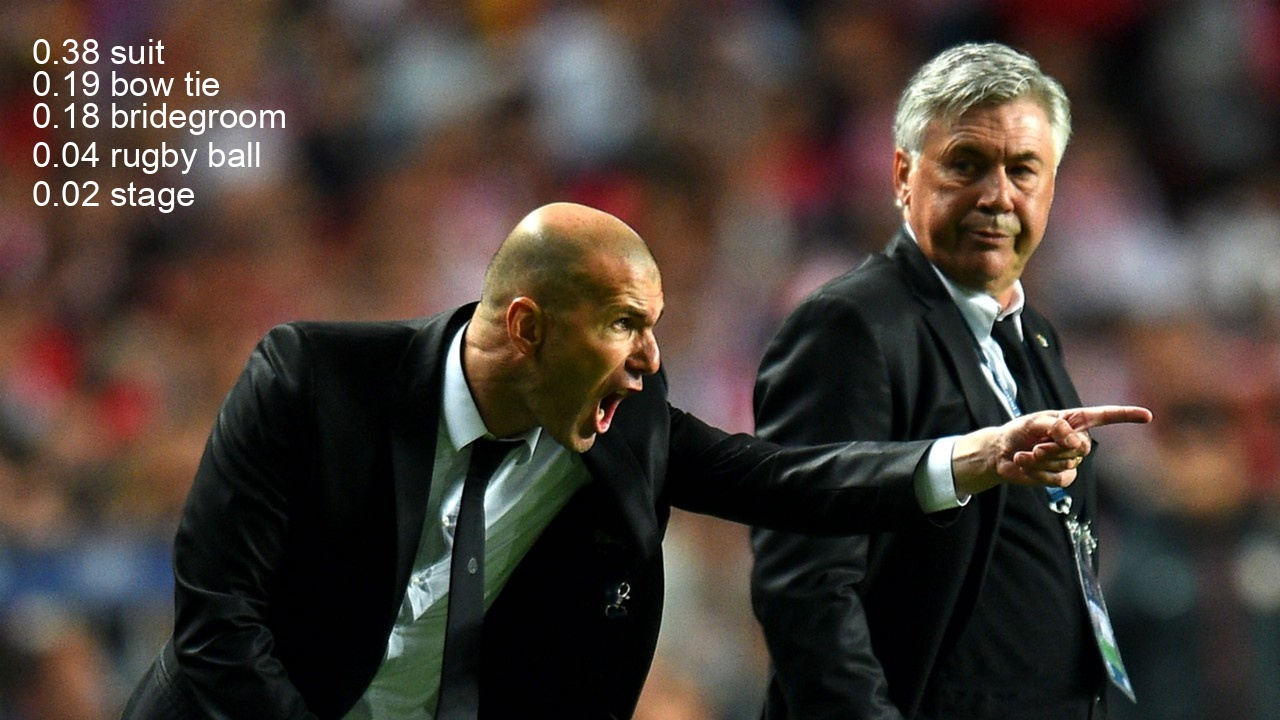

In [3]:
!python classify/predict.py --weights yolov5s-cls.pt --img 224 --source data/images
display.Image(filename='runs/predict-cls/exp/zidane.jpg', width=600)

In [ ]:
# Descargar Imagenet val (6.3G, 50000 imágenes)
!bash data/scripts/get_imagenet.sh --val

Se truncaron las últimas líneas 5000 del resultado de transmisión.
mv: cannot stat 'ILSVRC2012_val_00045001.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045002.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045003.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045004.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045005.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045006.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045007.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045008.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045009.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045010.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045011.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045012.JPEG': No such file or directory
mv: cannot stat 'ILSVRC2012_val_00045013.JPEG

In [ ]:
# Validar YOLOv5s en Imagenet val
!python classify/val.py --weights yolov5s-cls.pt --data ../datasets/imagenet --img 224 --half

classify/val: data=../datasets/imagenet, weights=['yolov5s-cls.pt'], batch_size=128, imgsz=224, device=, workers=8, verbose=True, project=runs/val-cls, name=exp, exist_ok=False, half=True, dnn=False
YOLOv5 🚀 v7.0-574-g1e7cf74c Python-3.13.18 torch-2.14.1+cpu CPU

Fusing layers... 
Model summary: 67 layers, 5,447,688 parameters, 0 gradients, 10.4 GFLOPs
Traceback (most recent call last):
  File "/content/yolov5/yolov5/classify/val.py", line 178, in <module>
    main(opt)
    ~~~~^^^^^
  File "/content/yolov5/yolov5/classify/val.py", line 173, in main
    run(**vars(opt))
    ~~~^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
  File "/content/yolov5/yolov5/classify/val.py", line 100, in run
    dataloader = create_classification_dataloader(
        path=test_dir, imgsz=imgsz, batch_size=batch_size, augment=False, rank=-1, workers=workers
    )
  File "/content/yolov5/yolov5/utils/dat

In [ ]:
# @title Seleccionar registrador YOLOv5 🚀 {run: 'auto'}
logger = "Comet"  # @param ['Comet', 'ClearML', 'TensorBoard']

if logger == "Comet":
    %pip install -q comet_ml
    import comet_ml

    comet_ml.init()
elif logger == "ClearML":
    %pip install -q clearml
    import clearml

    clearml.browser_login()
elif logger == "TensorBoard":
    %load_ext tensorboard
    %tensorboard --logdir runs/train

COMET WARNING: comet_ml.init() is deprecated and will be removed soon. Please use comet_ml.login()


Please paste your Comet API key from https://www.comet.com/api/my/settings/
(api key may not show as you type)
Comet API key: ··········


COMET INFO: Valid Comet API Key saved in /root/.comet.config (set COMET_CONFIG to change where it is saved).


In [ ]:
# Entrenar Clasificación YOLOv5s en Imagenette160 por 5 épocas
!python classify/train.py --model yolov5s-cls.pt --data imagenette160 --epochs 5 --img 224 --cache


I0000 00:00:1795028380.967134   57087 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795028383.767810   57087 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
classify/train: model=yolov5s-cls.pt, data=imagenette160, epochs=5, batch_size=64, imgsz=224, nosave=False, cache=ram, device=, workers=8, project=runs/train-cls, name=exp, exist_ok=False, pretrained=True, optimizer=Adam, lr0=0.001, decay=5e-05, label_smoothing=0.1, cutoff=None, dropout=None, verbose=False, seed=0, local_rank=-1
github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 v7.0-574-g1e7cf74c Python-3.13.18 torch-2.14.1+cpu CPU

TensorBoard: Start with 'tensorboard --logdir runs/train-cls', view at http://localhost:6006/

Dataset not found ⚠️, missing path /content/yolov5/datasets/imagenette160, attempting download...
######################################################################## 100.0%
Unzipping /content/